# TMR4240 Project Part 2 – Simulations 2–7 and extra credit

This notebook runs the Part 2 mandatory simulations (except Simulation 1),
computes the performance metrics used in the report, and saves every report
figure as PDF to `figures/` (prefix `p2_`).

* Every simulation is run **through its preset in `run_case_part_2.py`**
  (`rc.sim2()`, …), so the notebook and `python run_case_part_2.py simN` always
  run the same scenario. The preset's own figures are closed; the figures
  are redrawn here from the returned logs so they can be saved under fixed
  names.
* All metric definitions are in `part_2/metrics.py`. Paired comparisons use
  the same metric and an evaluation window of the same length.
* Simulations 4 (stage c), 5, 6, 7 and the extra credit need `SELECTED_OBSERVER`
  in `run_case_part_2.py`. Run Simulation 4 first, choose the observer from
  stages (a) and (b), set it, restart the kernel and run the notebook again.
* Sensor noise is off in all mandatory simulations; dt = 0.1 s everywhere.

## Setup

In [1]:
import sys
sys.path.insert(0, "..")

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

import run_case_part_2 as rc
from models.thruster_dynamics import ThrusterSet
from part_2 import metrics as m
from part_2.config import Part2SimConfig, default_thrusters_part_2
from part_2.thrust_allocation import ThrustAllocator
from simulation.plotter import plot_current, plot_time_histories, plot_wrench, plot_xy
from simulation.plotter_part_2 import (plot_observer, plot_observer_error,
                                       plot_thruster_setpoints, plot_waves,
                                       plot_wind_field, plot_wrench_residual)

THRUSTERS = default_thrusters_part_2()
FIG_DIR = Path("..") / "figures"
FIG_DIR.mkdir(exist_ok=True)

HOLD = 300.0                  # four-corner hold time per leg [s] (prescribed)
EVAL_LEN = 500.0              # length of every observer / station-keeping evaluation window [s]
SIM4_WINDOW = (100.0, 600.0)  # 600 s runs: skip the first 100 s (start-up transient)
SIM6_WINDOW = (500.0, 1000.0) # 1000 s run: last 500 s, same length as SIM4_WINDOW
SIM7_BEFORE = (rc.SIM7_T_FAIL - EVAL_LEN, rc.SIM7_T_FAIL)                 # before the failure
SIM7_AFTER = (rc.SIM7_T_FAIL + 100.0, rc.SIM7_T_FAIL + 100.0 + EVAL_LEN)  # after its transient
SIM5_STEP_DEG = 10.0          # direction step of the Simulation 5 sweep (prescribed)
for w in (SIM4_WINDOW, SIM6_WINDOW, SIM7_BEFORE, SIM7_AFTER):
    assert w[1] - w[0] == EVAL_LEN


def save(fig, name):
    fig.savefig(FIG_DIR / f"p2_{name}.pdf", bbox_inches="tight")


def show_table(rows, title=""):
    # rows: list of dicts with the same keys
    if title:
        print(title)
    keys = list(rows[0].keys())
    fmt = lambda v: f"{v:.2f}" if isinstance(v, float) else str(v)
    width = [max(len(k), *(len(fmt(r[k])) for r in rows)) for k in keys]
    print("  ".join(k.rjust(w) for k, w in zip(keys, width)))
    for r in rows:
        print("  ".join(fmt(r[k]).rjust(w) for k, w in zip(keys, width)))
    print()


def selected_or_none():
    if rc.SELECTED_OBSERVER is None:
        print("SELECTED_OBSERVER is not set in run_case_part_2.py - run Part 2, "
              "Simulation 4, choose the observer, set it and restart the kernel.")
    return rc.SELECTED_OBSERVER

## Subsystem checks — run these first

The Part 2 automated checks (`python check.py --part 2`), on the default
constructors. All eight should pass before the simulations are used in the
report.

In [2]:
from simulation.checks import print_result
from simulation.checks_part_2 import ALL_CHECKS, run_check

check_results = {key: run_check(key) for key in ALL_CHECKS}
for res in check_results.values():
    print_result(res)
    print()

NPO slowest pole: -0.0303  (stable)
NPO slowest pole: -0.0303  (stable)
NPO slowest pole: -0.0303  (stable)
NPO slowest pole: -0.0303  (stable)
[     PASS      ] current (part_2): direction conventions
                  ok    from east -> flows west: [V_N, V_E] = [0, -0.5]  [got [-0.  -0.5]]
                  ok    components 2-5 of the generalized vector are zero  [got [0. 0. 0. 0.]]
                  ok    rotation start: from north -> [-0.5, 0]  [got [-0.5  0. ]]
                  ok    rotation end: from east -> [0, -0.5]  [got [-0.  -0.5]]

[     PASS      ] wind (part_2): loads, gust, direction variation
                  ok    gust off, head wind: Fx < 0 and |Fx| = U^2*Cx(180 deg) within 5%  [Fx = -2.86 kN vs expected -2.86 kN]
                  ok    gust off, wind from east at psi=0: Fy < 0 and dominant  [Fx = -0.00 kN, Fy = -10.92 kN]
                  ok    relative wind: sailing into the wind increases |Fx|  [Fx = -4.12 kN moving vs -2.86 kN at rest]
                  ok   

## Part 2, Simulation 2 — DP, allocation and thruster dynamics

Four-corner test (five legs of 300 s) with the reference model and the
constrained Part 2 thruster dynamics (maximum thrust, thrust ramp rate,
12°/s azimuth slew); no current, wind, waves or observer. Preset: `rc.sim2`.

Required evidence: position and heading vs. desired (the plots label the
reference-model output "setpoint"), xy trajectory, desired vs. applied wrench,
commanded vs. actual thrust and azimuth, reference vs. actual velocities, the
residual wrench, and the intervals where an actuator limit is active.

NPO slowest pole: -0.0303  (stable)


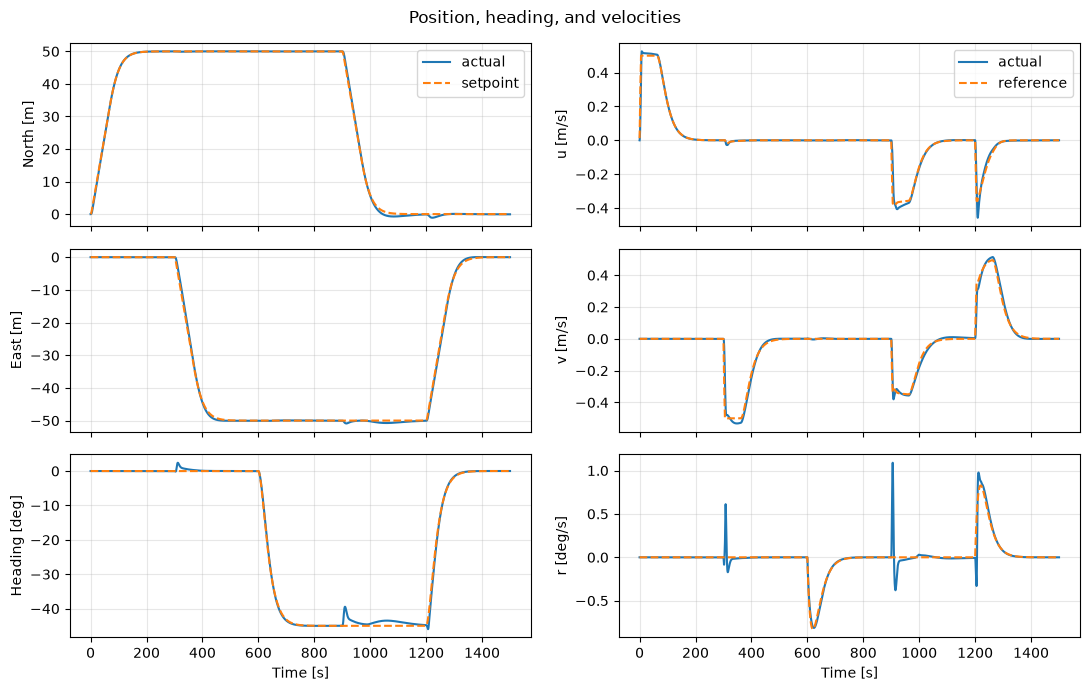

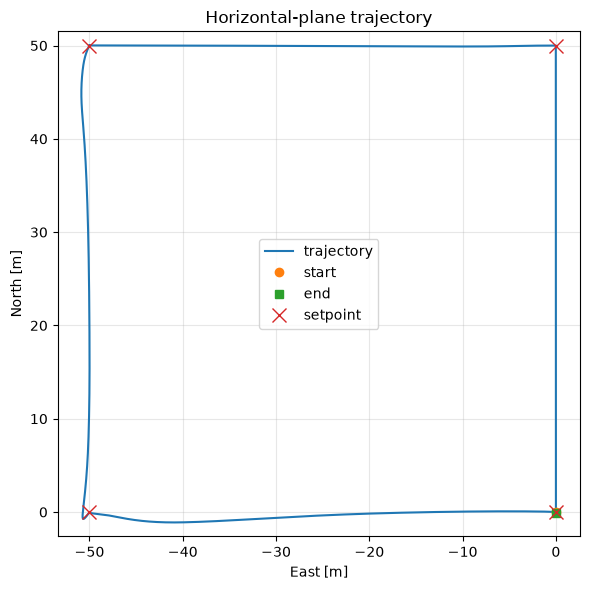

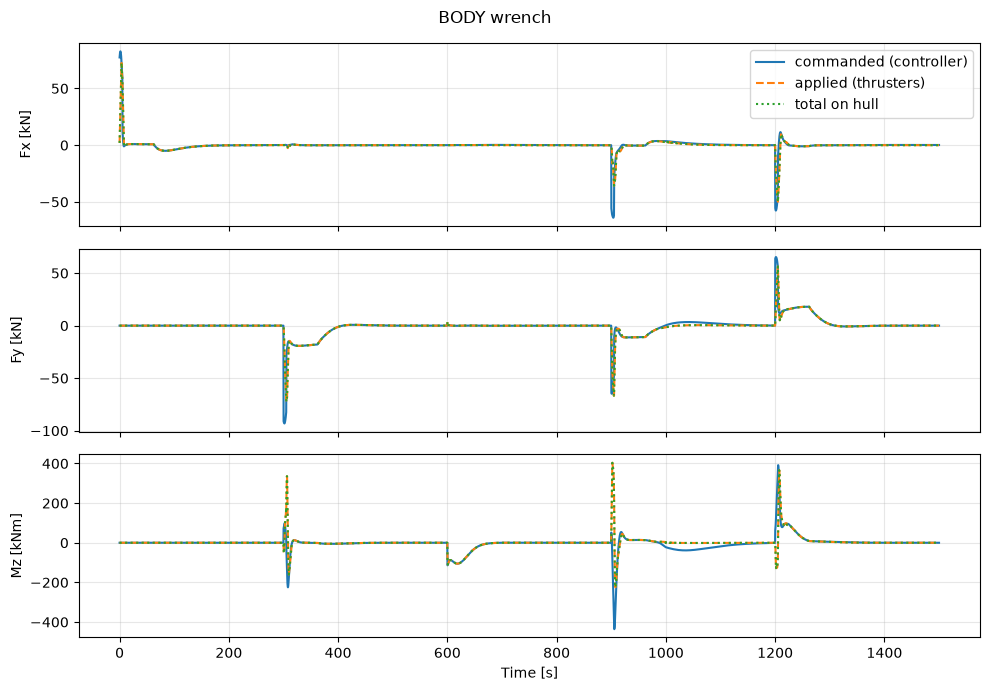

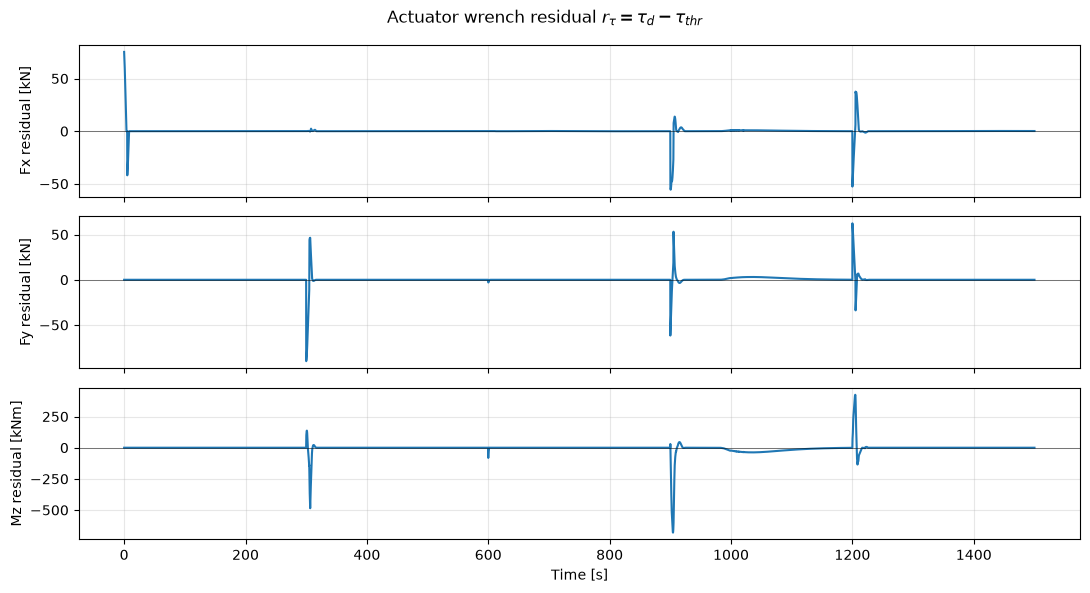

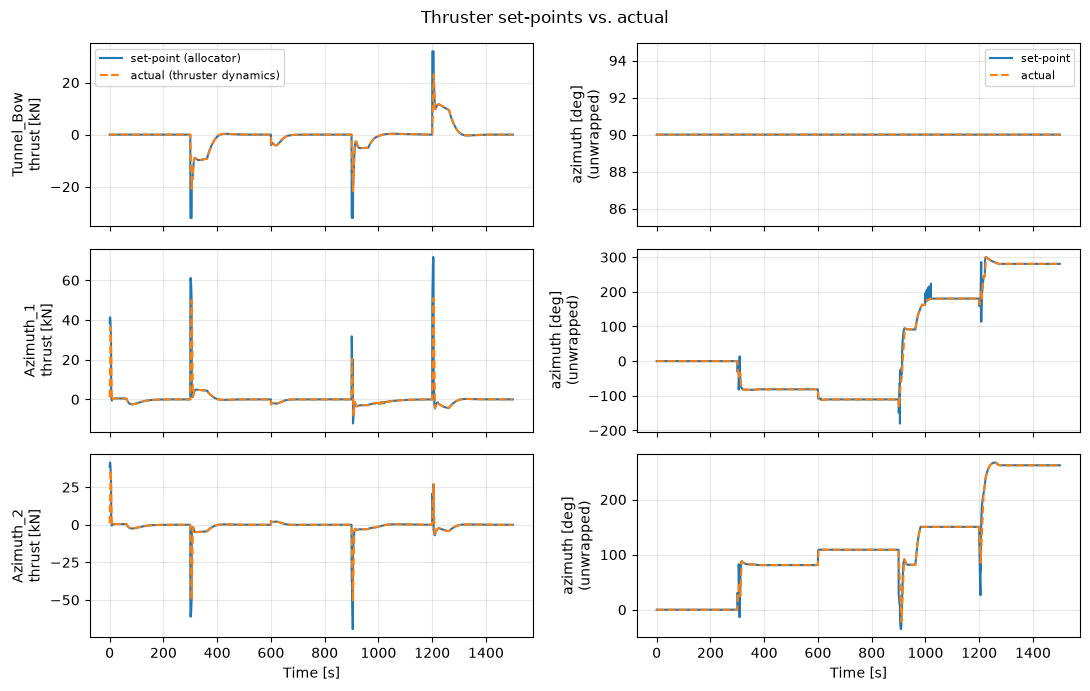

In [3]:
logs2 = rc.sim2()
plt.close("all")

save(plot_time_histories(logs2), "sim2_time")        # N, E, psi vs desired; u, v, r vs reference
save(plot_xy(logs2), "sim2_xy")
save(plot_wrench(logs2), "sim2_wrench")              # desired vs applied wrench
save(plot_wrench_residual(logs2), "sim2_residual")   # r_tau = tau_c - tau_thr
save(plot_thruster_setpoints(logs2), "sim2_thrusters")
plt.show()

In [4]:
all2 = m.window(logs2)
show_table(m.leg_table(logs2, HOLD, 5),
           "Per leg: tracking error w.r.t. the reference trajectory, settling time to "
           "1 m / 1 deg of the corner, final error")
show_table([m.actuator_effort(logs2, THRUSTERS, all2)], "Actuator effort, whole run")
show_table([m.residual_metrics(logs2, all2)],
           "Allocation residual r_tau (time_above_tol: |r| > 1 kN or 10 kNm)")
show_table([{"thruster": k, **v} for k, v in m.limit_summary(logs2, THRUSTERS).items()],
           "Share of time [%] each actuator limit is active")

print("Intervals (>= 2 s) with an active limit:")
for name, lims in m.active_limits(logs2, THRUSTERS).items():
    for kind, mask in lims.items():
        iv = m.intervals(logs2.t, mask, min_duration=2.0)
        if iv:
            print(f"  {name:11s} {kind:9s} " + ", ".join(f"{a:.0f}-{b:.0f} s" for a, b in iv))

Per leg: tracking error w.r.t. the reference trajectory, settling time to 1 m / 1 deg of the corner, final error
leg  max_pos_m  rms_pos_m  max_psi_deg  rms_psi_deg  settle_s  final_pos_m  final_psi_deg
  1       0.83       0.22         0.00         0.00    145.60         0.00           0.00
  2       1.76       0.72         2.40         0.48    134.00         0.01          -0.00
  3       0.07       0.04         1.01         0.31    110.80         0.01          -0.00
  4       1.45       0.82         5.55         1.43    215.90         0.10           0.20
  5       1.51       0.65         3.60         0.76    134.90         0.06           0.00

Actuator effort, whole run
util_mean_pct  thrust_kN  thrust_rate_kN_s  azimuth_travel_deg
         2.15       4.12              0.60             1461.89

Allocation residual r_tau (time_above_tol: |r| > 1 kN or 10 kNm)
max_rX_kN  max_rY_kN  max_rN_kNm  rms_rX_kN  rms_rY_kN  rms_rN_kNm  time_above_tol_pct
    75.35      89.98      680.97       4

## Part 2, Simulation 3 — DP and environmental forces

The same four-corner test in the Simulation 1 environment (current 0.2 m/s from
east, wind 10 m/s from north with gust and ±5° direction, waves from north-east
Hs = 1.5 m, Tp = 8 s), raw feedback (measured pose and simulated velocity), no
observer. Preset: `rc.sim3`. Compared with Simulation 2 over the same 1500 s
and the same legs.

NPO slowest pole: -0.0303  (stable)


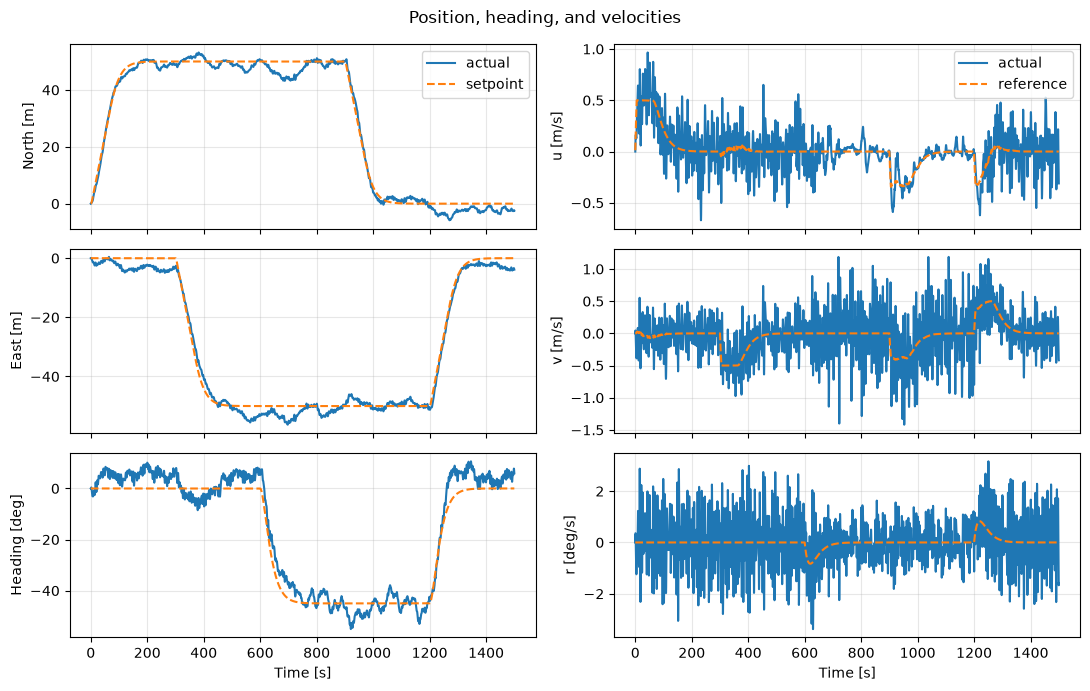

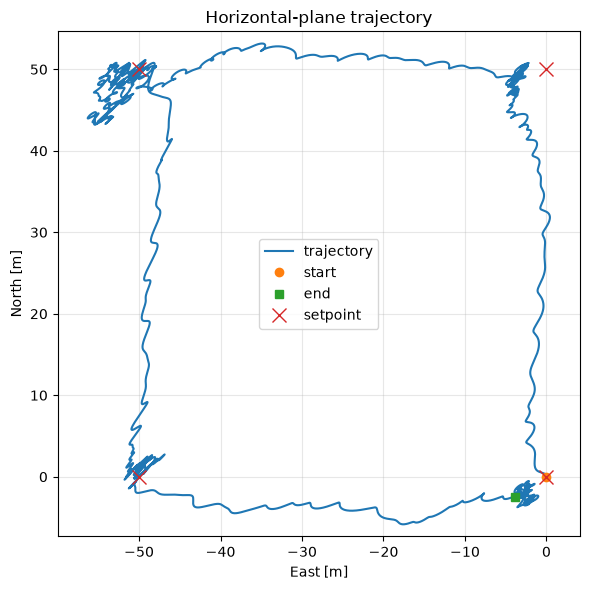

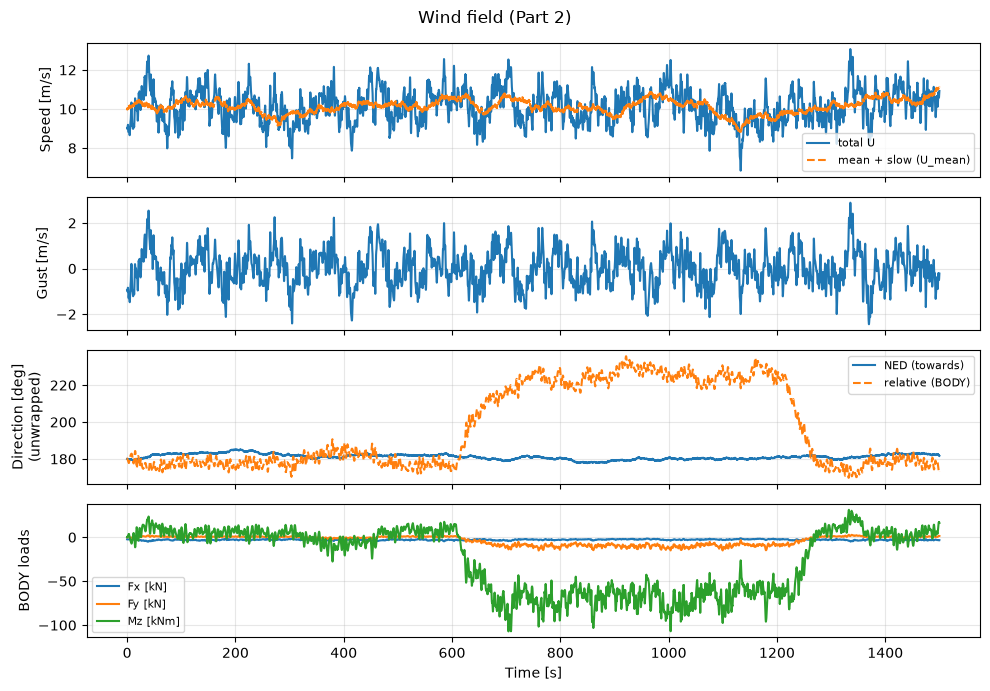

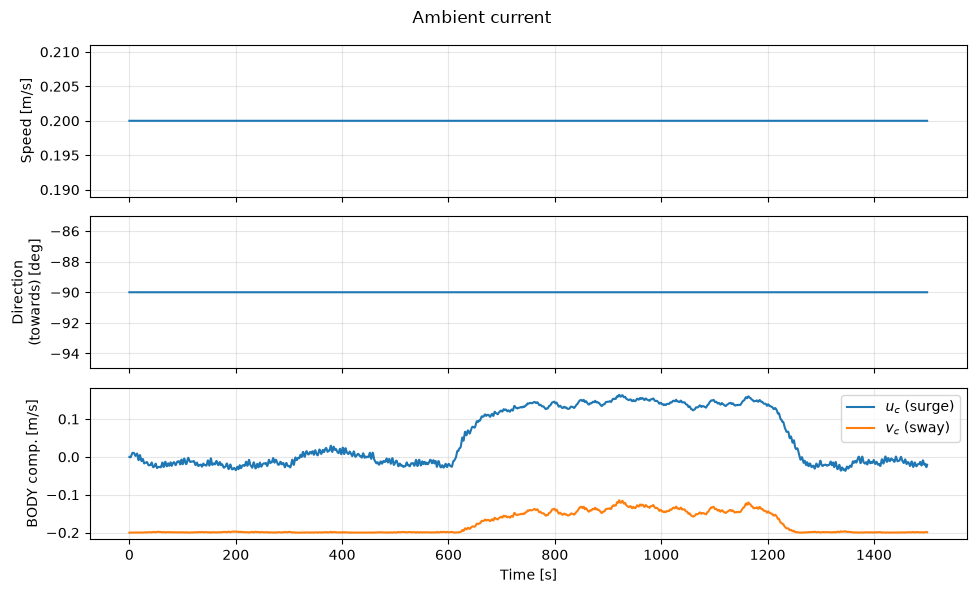

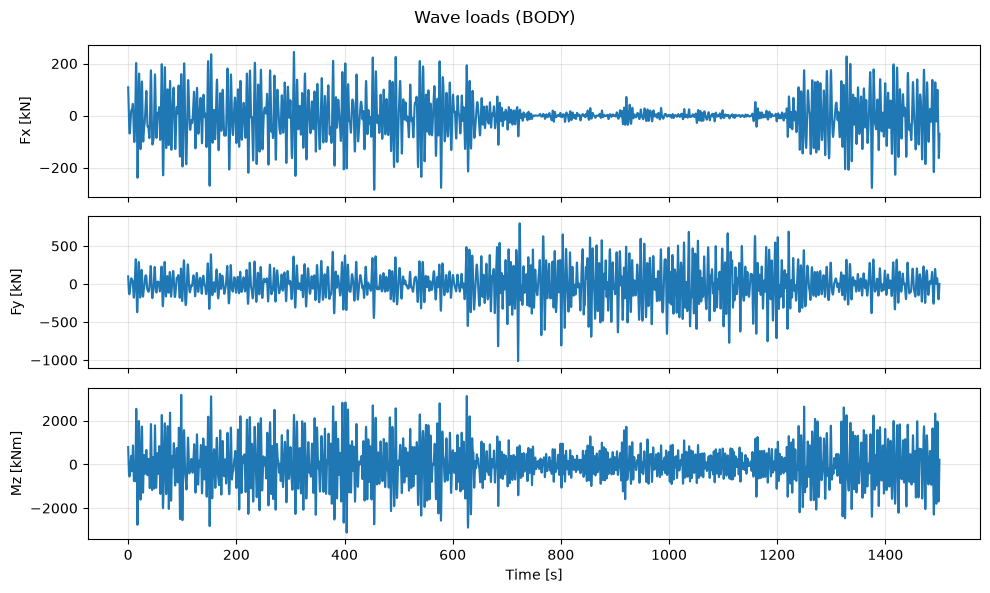

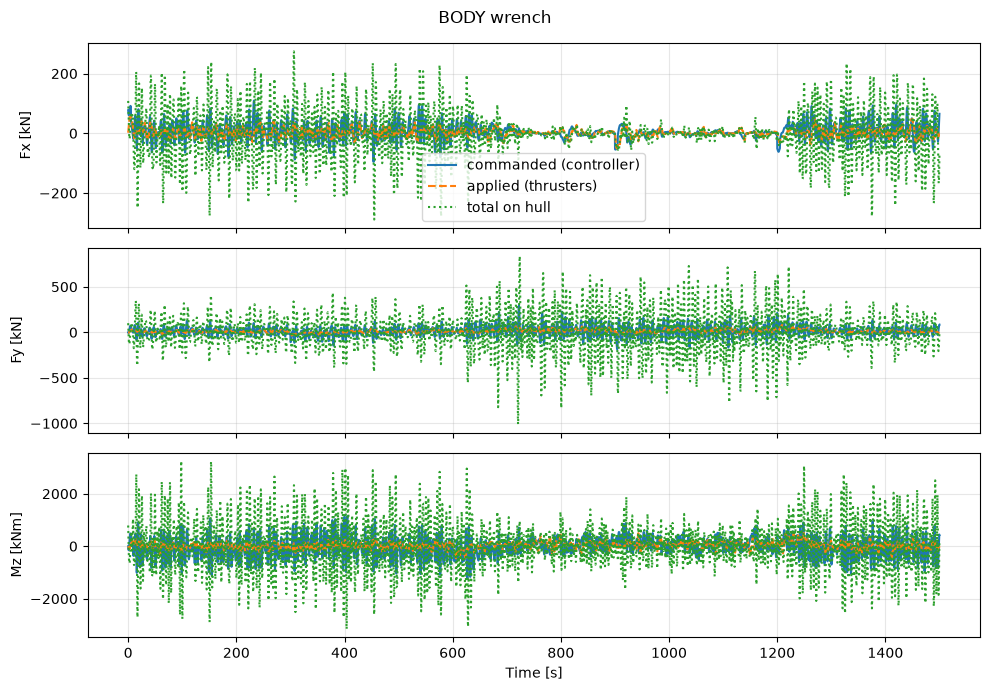

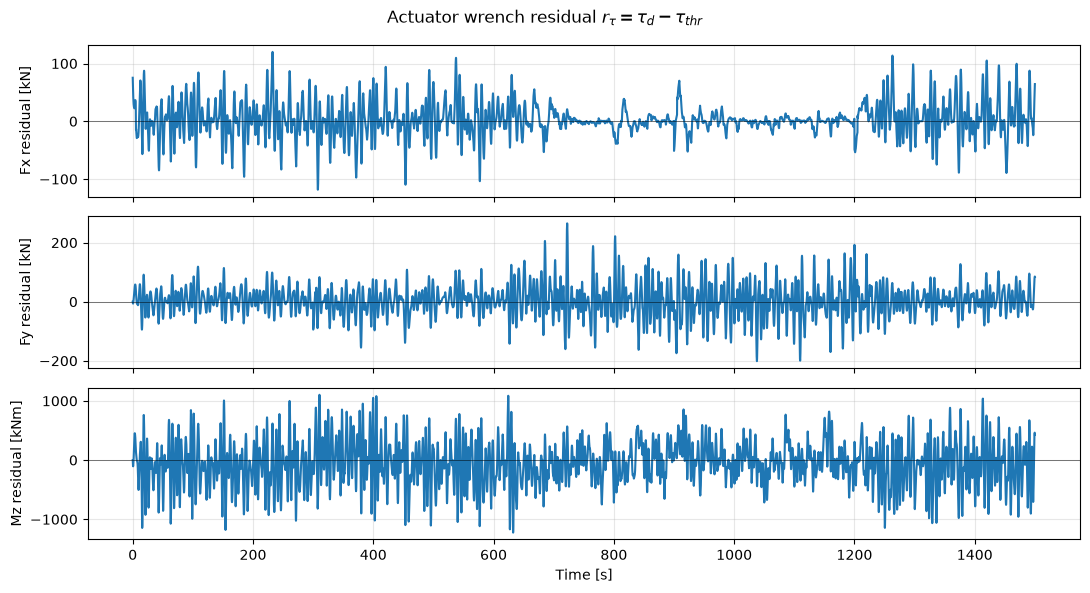

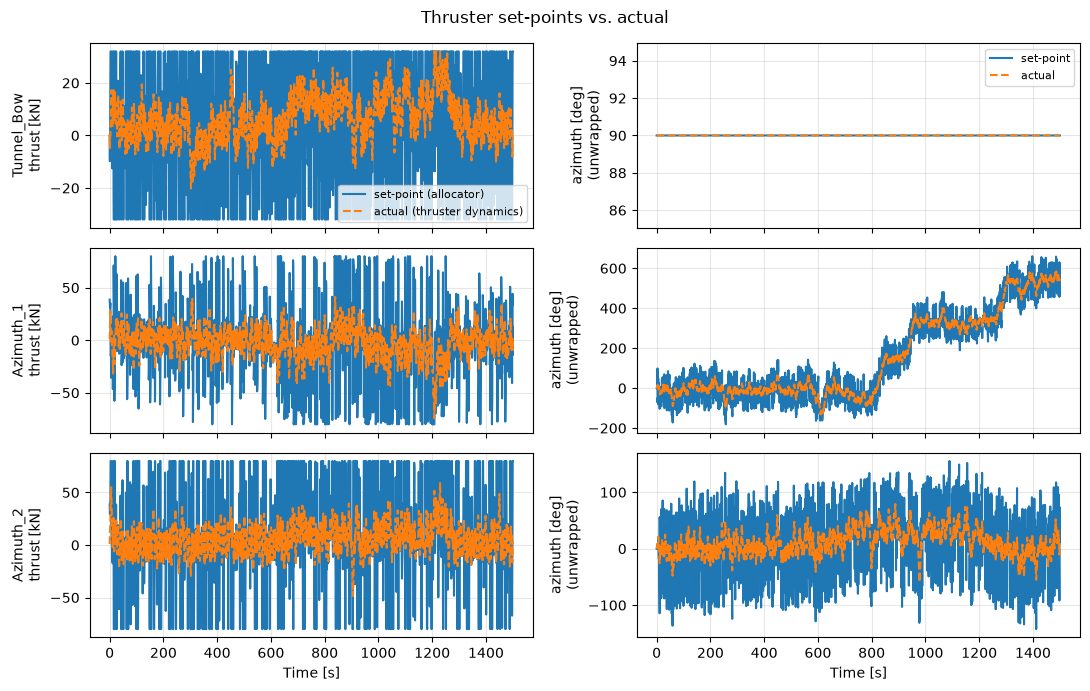

In [5]:
logs3 = rc.sim3()
plt.close("all")

save(plot_time_histories(logs3), "sim3_time")
save(plot_xy(logs3), "sim3_xy")
save(plot_wind_field(logs3), "sim3_wind")
save(plot_current(logs3), "sim3_current")
save(plot_waves(logs3), "sim3_waves")
save(plot_wrench(logs3), "sim3_wrench")
save(plot_wrench_residual(logs3), "sim3_residual")
save(plot_thruster_setpoints(logs3), "sim3_thrusters")
plt.show()

In [6]:
show_table(m.leg_table(logs3, HOLD, 5), "Simulation 3 per leg")


def four_corner_summary(label, logs):
    legs = m.leg_table(logs, HOLD, 5)
    sel = m.window(logs)
    eff = m.actuator_effort(logs, THRUSTERS, sel)
    res = m.residual_metrics(logs, sel)
    return {"run": label,
            "max_pos_m": max(r["max_pos_m"] for r in legs),
            "rms_pos_m": float(np.mean([r["rms_pos_m"] for r in legs])),
            "max_psi_deg": max(r["max_psi_deg"] for r in legs),
            "rms_psi_deg": float(np.mean([r["rms_psi_deg"] for r in legs])),
            "legs_settled": sum(np.isfinite(r["settle_s"]) for r in legs),
            "util_pct": eff["util_mean_pct"], "thrust_rate_kN_s": eff["thrust_rate_kN_s"],
            "az_travel_deg": eff["azimuth_travel_deg"],
            "rms_rN_kNm": res["rms_rN_kNm"], "resid_time_pct": res["time_above_tol_pct"]}


show_table([four_corner_summary("Sim 2 (no environment)", logs2),
            four_corner_summary("Sim 3 (environment)", logs3)],
           "Simulation 2 vs 3 (rms values are the mean over the five legs)")
show_table([{"thruster": k, **v} for k, v in m.limit_summary(logs3, THRUSTERS).items()],
           "Simulation 3: share of time [%] each actuator limit is active")

Simulation 3 per leg
leg  max_pos_m  rms_pos_m  max_psi_deg  rms_psi_deg  settle_s  final_pos_m  final_psi_deg
  1       5.79       3.43        10.11         5.62       nan         3.01           6.83
  2       6.26       3.19         8.51         4.44       nan         3.28           5.45
  3       8.72       4.30         9.36         4.69    277.90         0.53          -1.77
  4       4.49       2.10        10.07         3.78       nan         1.21           1.97
  5       6.02       3.54        11.82         5.89       nan         4.54           6.11

Simulation 2 vs 3 (rms values are the mean over the five legs)
                   run  max_pos_m  rms_pos_m  max_psi_deg  rms_psi_deg  legs_settled  util_pct  thrust_rate_kN_s  az_travel_deg  rms_rN_kNm  resid_time_pct
Sim 2 (no environment)       1.76       0.49         5.55         0.60             5      2.15              0.60        1461.89       44.13           12.91
   Sim 3 (environment)       8.72       3.31        11.82      

## Part 2, Simulation 4 — Observer comparison and selection

Preset: `rc.sim4`, in three stages. **(a)** Fixed desired wrench
τ_c = [2, 2, 2]·10³ (N, N, N m), controller out of the loop, Simulation 1
environment, 600 s, both observers, with and without waves. **(b)** 300 s
with the estimate started at `rc.OBSERVER_OFFSET` (the engine resets the
observer on the true pose). **(c)** Closed-loop station keeping at the origin
for 600 s, raw feedback vs. the selected observer; this stage only runs once
`SELECTED_OBSERVER` is set.

Metrics (`m.observer_metrics`) are evaluated over `SIM4_WINDOW`. The
wave-filtering ratio is only meaningful in the runs with waves. True velocity
is used only for validation, never as observer input. `rc.OBSERVER_OFFSET`
is the example value from the course code: choose and justify your own.

For the convergence time, each observer is also run once more exactly like
stage (b) but started on the true pose. The true motion is identical, so the
difference between the two estimates is only the effect of the initial
error, separated from the wave and model errors both runs share.

NPO slowest pole: -0.0303  (stable)
NPO slowest pole: -0.0303  (stable)
NPO slowest pole: -0.0303  (stable)

Part 2, Simulation 4: stages (a) and (b) are done and plotted, and their logs are returned.
Compare the observers on that evidence, set SELECTED_OBSERVER at the top of run_case_part_2.py,
then run sim4 again for stage (c), the raw-vs-observer closed loop.
(In a notebook, restart the kernel or importlib.reload(rc) first, so the new value is picked up.)


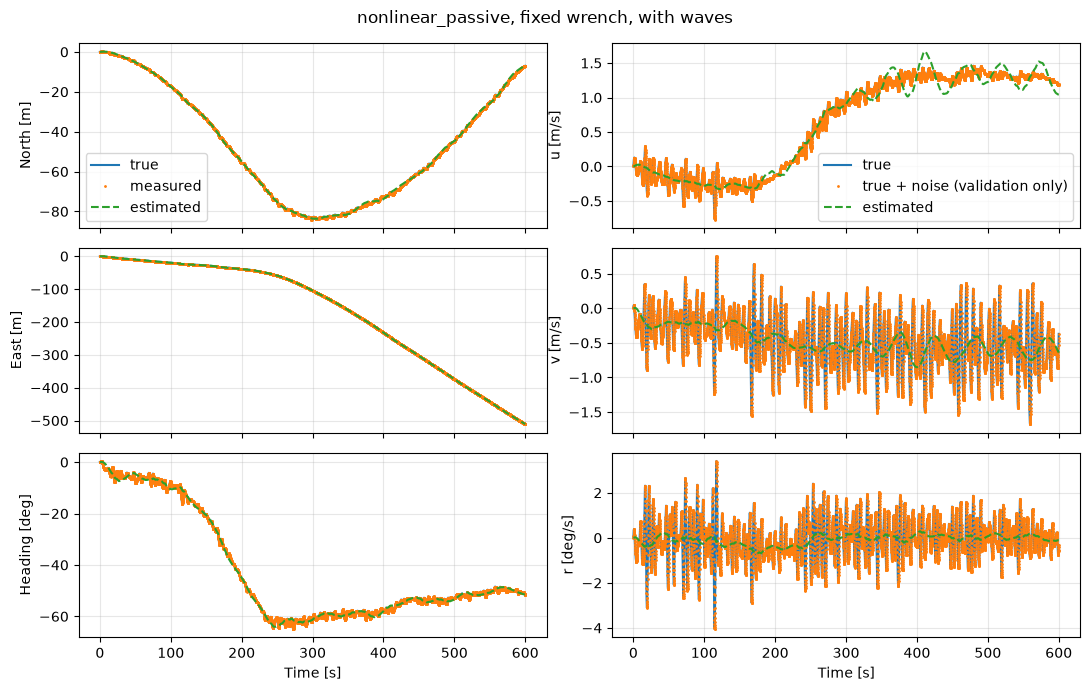

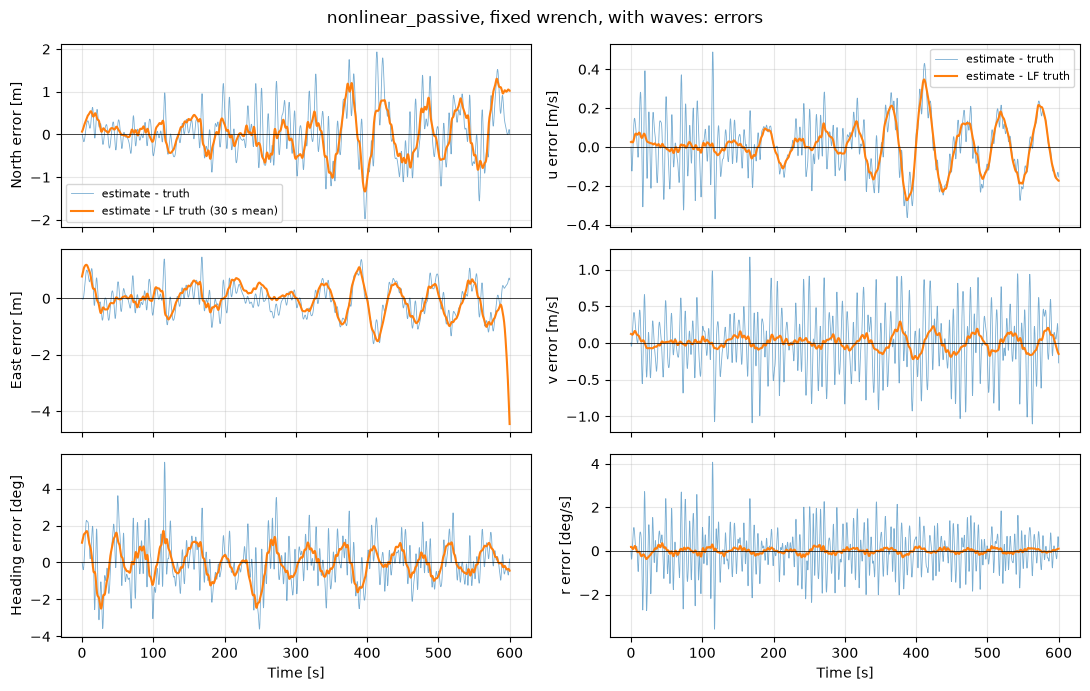

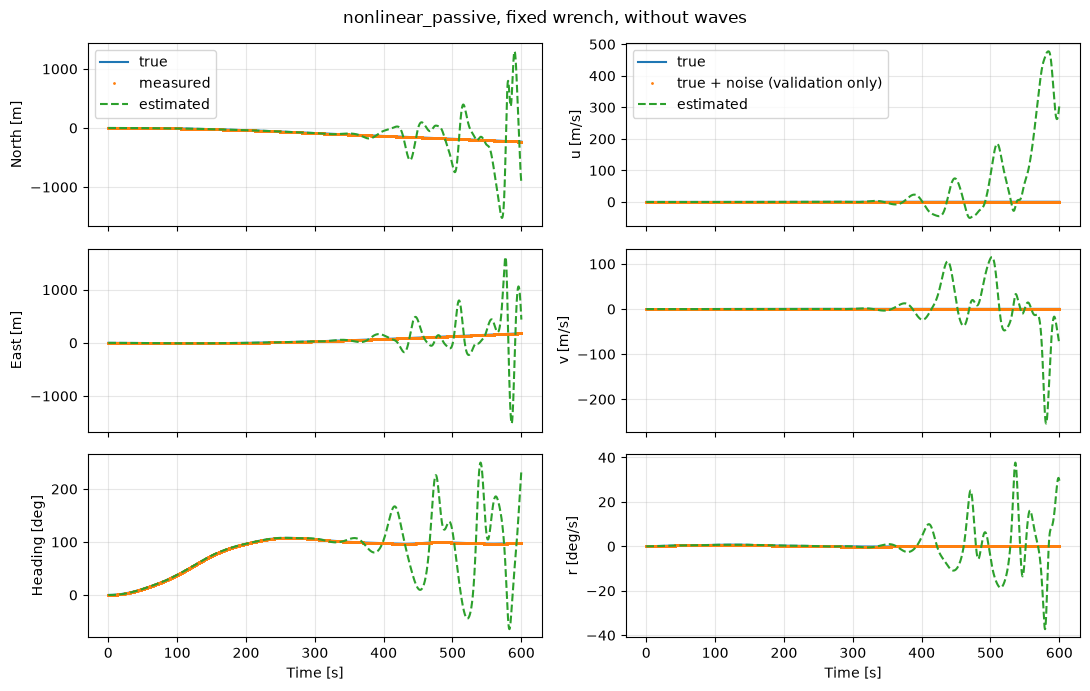

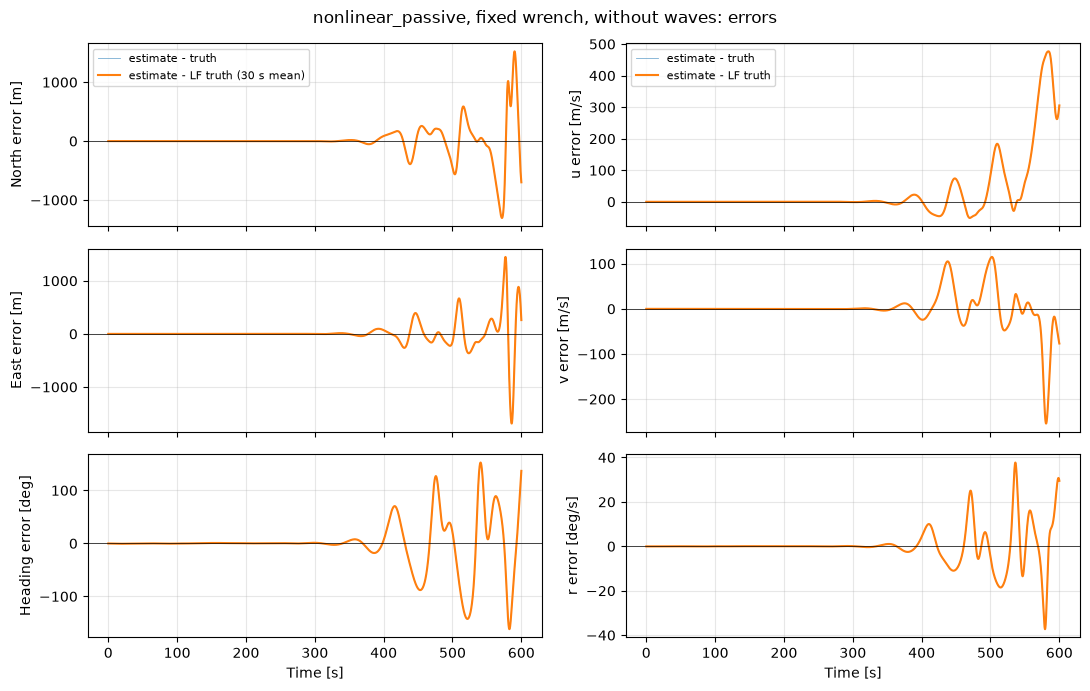

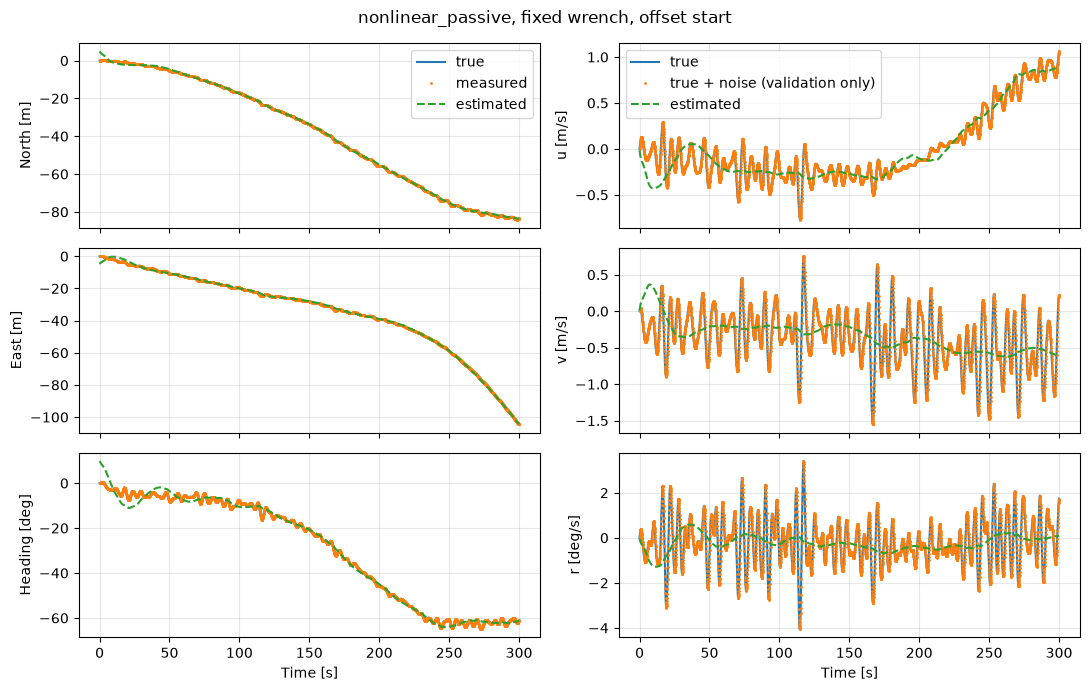

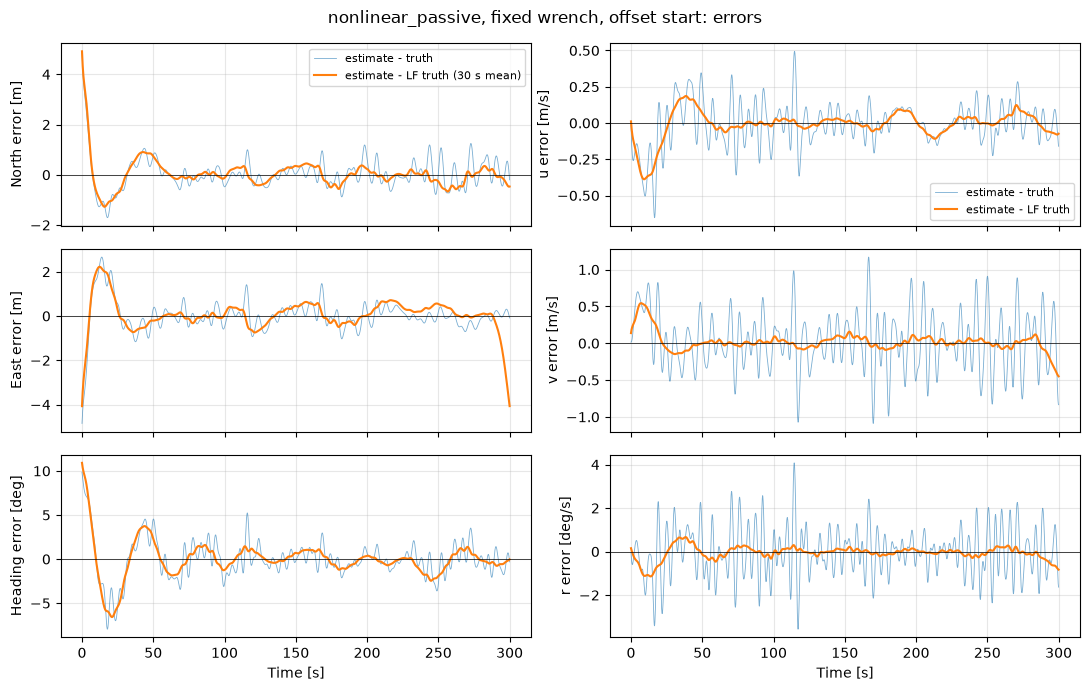

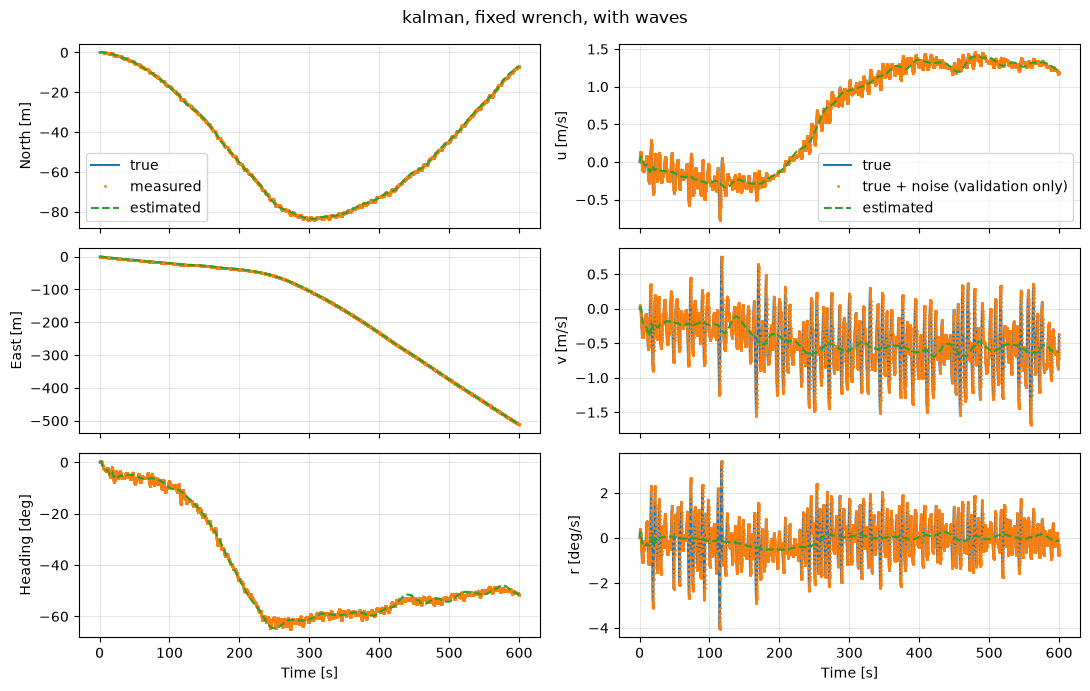

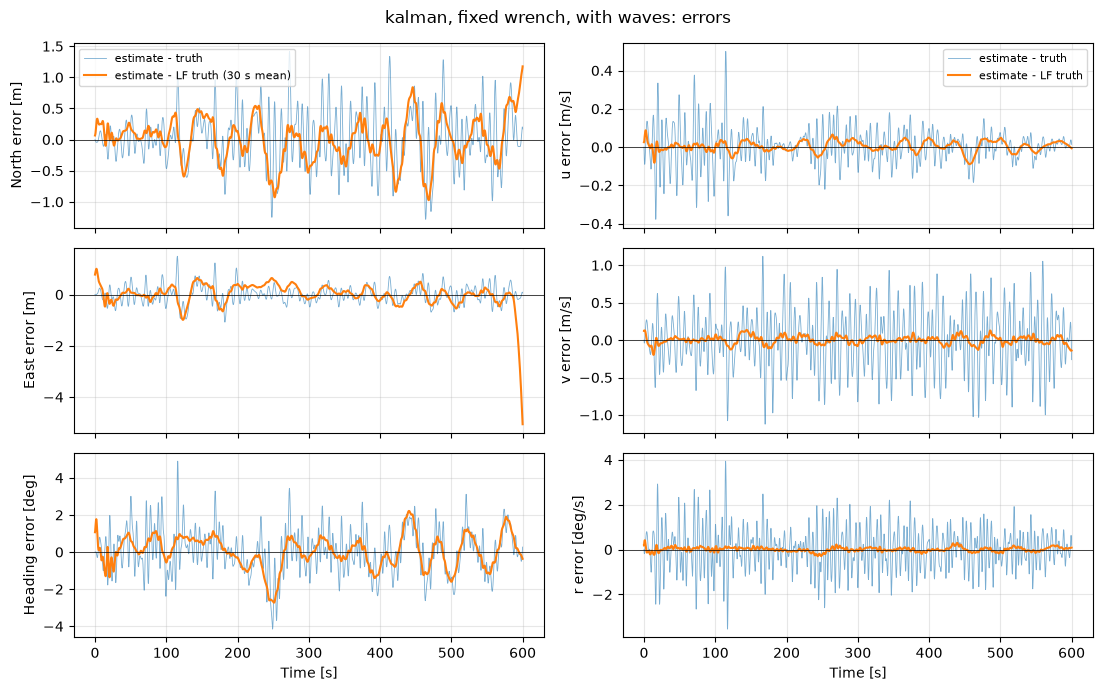

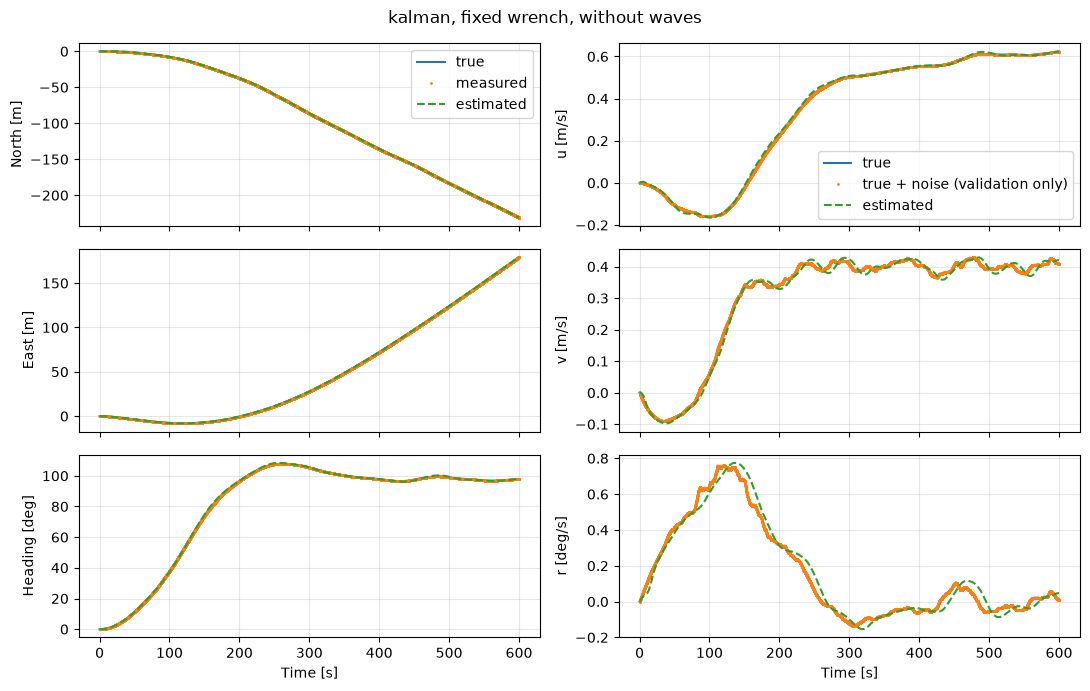

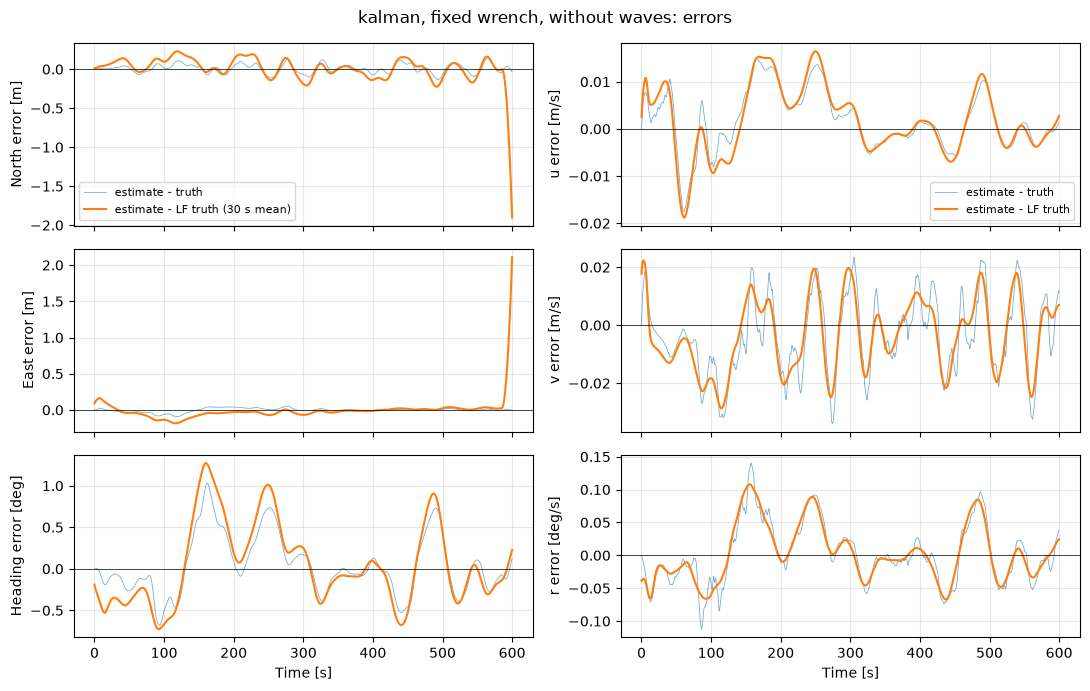

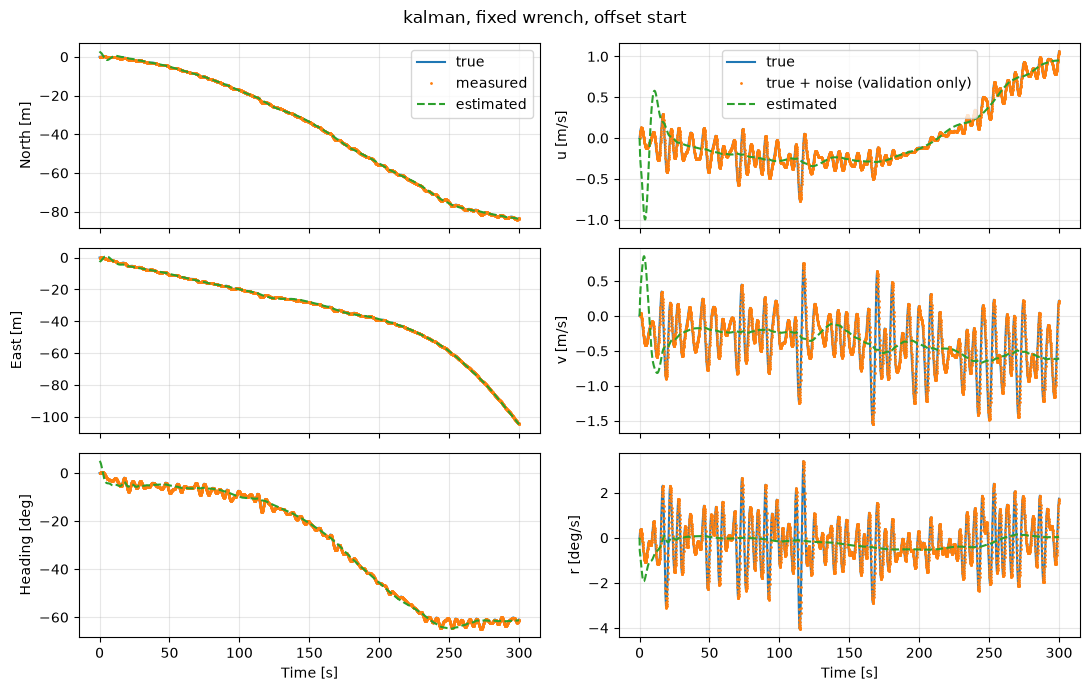

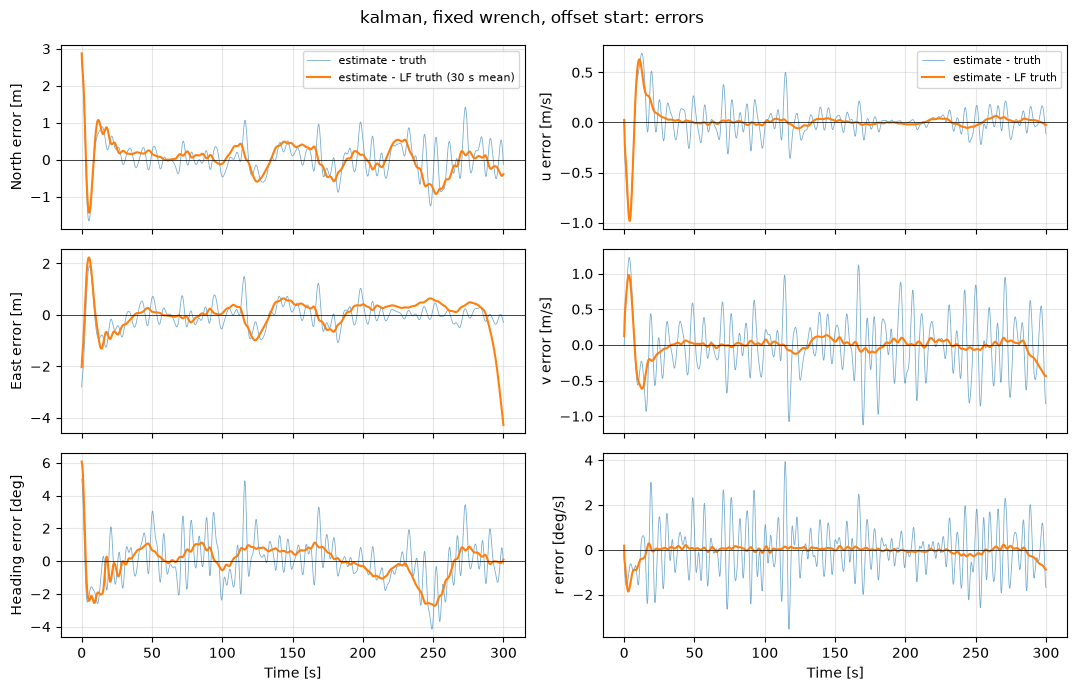

(a) accuracy and wave filtering, window (100.0, 600.0) s (wf_ratio < 1: wave-frequency motion attenuated)
         observer           case  rms_lf_N  wf_ratio_N  rms_lf_E  wf_ratio_E  rms_lf_psi  wf_ratio_psi  rms_vel_u  rms_vel_v  rms_vel_r
nonlinear_passive     with waves      0.50        0.66      0.53        0.88        0.74          0.54       0.11       0.10       0.11
nonlinear_passive  without waves    181.52      359.49    175.89      680.89       47.97        191.09      94.47      41.97       8.24
           kalman     with waves      0.37        0.62      0.32        0.75        0.91          0.50       0.03       0.05       0.10
           kalman  without waves      0.11        1.20      0.05        1.01        0.51          1.20       0.01       0.01       0.04

(a) smoothness (extra rate of change vs LF truth), lag behind LF truth [s], total error
         observer           case  rms_tot_N  rough_N  lag_N_s  rms_tot_E  rough_E  lag_E_s  rms_tot_psi  rough_psi  lag_psi_s

In [7]:
KINDS = ("nonlinear_passive", "kalman")
out4 = rc.sim4()
plt.close("all")

for kind in KINDS:
    for key, tag in (("with waves", "waves"), ("without waves", "nowaves"), ("offset start", "offset")):
        L = out4[(kind, key)]
        stage = "sim4b" if key == "offset start" else "sim4a"
        fig = plot_observer(L); fig.suptitle(f"{kind}, fixed wrench, {key}"); save(fig, f"{stage}_{kind}_{tag}")
        fig = plot_observer_error(L); fig.suptitle(f"{kind}, fixed wrench, {key}: errors")
        save(fig, f"{stage}_{kind}_{tag}_error")
plt.show()

sel = lambda L: m.window(L, *SIM4_WINDOW)
rows_a = [(k, c, out4[(k, c)]) for k in KINDS for c in ("with waves", "without waves")]
show_table([{"observer": k, "case": c, **{q: v for q, v in m.observer_metrics(L, sel(L)).items()
                                          if q.startswith(("rms_lf", "wf_ratio", "rms_vel"))}}
            for k, c, L in rows_a],
           f"(a) accuracy and wave filtering, window {SIM4_WINDOW} s "
           "(wf_ratio < 1: wave-frequency motion attenuated)")
show_table([{"observer": k, "case": c, **{q: v for q, v in m.observer_metrics(L, sel(L)).items()
                                          if q.startswith(("rough", "lag", "rms_tot"))}}
            for k, c, L in rows_a],
           "(a) smoothness (extra rate of change vs LF truth), lag behind LF truth [s], total error")

In [8]:
# (b) convergence: reference run identical to the preset's offset run, but
# started on the true pose
ref4 = {}
fixed = rc.WrenchSequence([(1.0, [2e3, 2e3, 2e3])])
for kind in KINDS:
    cfg = Part2SimConfig(dt=rc.DT, T=300.0, use_reference=False, use_observer=True,
                         observer_type=kind)
    sim = rc.make_sim(cfg, fixed)
    sim.reset_state()
    current, wind, waves = rc.environment()
    ref4[kind] = sim.run(np.zeros(6), current=current, wind=wind, waves=waves)

print("Initial offset (N, E, psi):", rc.OBSERVER_OFFSET[[0, 1]], "m,",
      np.degrees(rc.OBSERVER_OFFSET[5]), "deg")
show_table([{"observer": k, **m.convergence_time(out4[(k, "offset start")], ref4[k])}
            for k in KINDS],
           "(b) time until the effect of the initial error is below 5 % of its initial value")

NPO slowest pole: -0.0303  (stable)
Initial offset (N, E, psi): [ 5. -5.] m, 10.0 deg
(b) time until the effect of the initial error is below 5 % of its initial value
         observer  t_conv_N_s  t_conv_E_s  t_conv_psi_s
nonlinear_passive       56.90       48.60         91.90
           kalman       34.90       31.80         16.50



**Choose the observer now.** Compare the tables and figures of (a) and (b),
set `SELECTED_OBSERVER` in `run_case_part_2.py`, restart the kernel and run
the notebook again; `rc.sim4()` then also runs stage (c).

In [9]:
# (c) closed-loop station keeping: raw feedback vs selected observer
closed4 = {}
OBS = selected_or_none()
if OBS is not None:
    closed4 = {"raw": out4[("closed loop", "raw measurements")],
               OBS: out4[("closed loop", f"observer {OBS}")]}
    for label, L in closed4.items():
        tag = "raw" if label == "raw" else "observer"
        save(plot_time_histories(L), f"sim4c_{tag}_time")
        save(plot_xy(L), f"sim4c_{tag}_xy")
        save(plot_thruster_setpoints(L), f"sim4c_{tag}_thrusters")
    save(plot_observer(closed4[OBS]), "sim4c_observer")
    plt.show()
    show_table([{"feedback": label, **m.station_keeping(L, *SIM4_WINDOW),
                 **m.actuator_effort(L, THRUSTERS, m.window(L, *SIM4_WINDOW))}
                for label, L in closed4.items()],
               f"(c) station keeping and actuator activity, window {SIM4_WINDOW} s")

SELECTED_OBSERVER is not set in run_case_part_2.py - run Part 2, Simulation 4, choose the observer, set it and restart the kernel.


## Part 2, Simulation 5 — Thrust-utilisation polar plot

Station keeping at [0, 0, 0] with the selected observer in co-linear wind
(12 m/s), current (0.2 m/s) and waves (Hs = 1.5 m, Tp = 8 s), swept from 0° to
350° in 10° steps, 600 s per direction, seed from the course code. The average
utilisation (`part_2/utilization.py`) is taken over the second half of each
run. Preset: `rc.sim5` (it runs the sweep and draws the three polar plots).

Runtime: 36 runs of 600 s, roughly 20–30 min.

In [ ]:
OBS = selected_or_none()
if OBS is not None:
    cap = rc.sim5(step_deg=SIM5_STEP_DEG)
    save(plt.gcf(), "sim5_polar")
    plt.show()
    pos_tot, psi_tot = rc.CAP_TOTAL_POS_LIMIT, rc.CAP_TOTAL_PSI_LIMIT_DEG
    show_table([{"from_deg": float(d), "util_pct": float(u),
                 "lf_pos_m": float(pl), "lf_psi_deg": float(np.degrees(ql)),
                 "tot_pos_m": float(pt), "tot_psi_deg": float(np.degrees(qt)),
                 "watch_circle": "ok" if pl <= cap.pos_limit and ql <= cap.psi_limit else "masked",
                 "operability": "ok" if pt <= pos_tot and np.degrees(qt) <= psi_tot else "masked"}
                for d, u, pl, ql, pt, qt in zip(cap.directions_deg, cap.utilization,
                                                cap.max_pos_dev_lf, cap.max_psi_dev_lf,
                                                cap.max_pos_dev_total, cap.max_psi_dev_total)],
               "Per direction: average utilisation and maximum LF / total deviation (second half)")

## Part 2, Simulation 6 — Observer robustness

Station keeping at the origin for 1000 s with the selected observer, unchanged
from Simulation 4, in the Simulation 1 current and wind but a heavier sea
(waves from north-east, Hs = 2.5 m, Tp = 10 s). Preset: `rc.sim6`.

To compare with the design sea (Simulation 4, stage c), the metrics are
evaluated over `SIM6_WINDOW`, which has the same length as `SIM4_WINDOW`
(500 s). The full 1000 s run is reported separately. Actuator saturation and
residuals are shown next to the observer errors, to separate limits caused
by the observer from limits caused by the actuators.

In [ ]:
def robustness_row(label, L, win):
    s = m.window(L, *win)
    obs = m.observer_metrics(L, s)
    res = m.residual_metrics(L, s)
    sat = m.limit_summary(L, THRUSTERS, s)
    return {"case": label, "window": f"{win[0]:.0f}-{win[1]:.0f}",
            **m.station_keeping(L, *win),
            "rms_lf_N": obs["rms_lf_N"], "rms_lf_E": obs["rms_lf_E"], "rms_lf_psi": obs["rms_lf_psi"],
            "wf_ratio_N": obs["wf_ratio_N"], "wf_ratio_E": obs["wf_ratio_E"],
            "lag_psi_s": obs["lag_psi_s"],
            "util_pct": m.actuator_effort(L, THRUSTERS, s)["util_mean_pct"],
            "max_sat_pct": max(v["saturated"] for v in sat.values()),
            "resid_time_pct": res["time_above_tol_pct"]}


OBS = selected_or_none()
if OBS is not None:
    logs6 = rc.sim6()
    plt.close("all")
    save(plot_time_histories(logs6), "sim6_time")
    save(plot_xy(logs6), "sim6_xy")
    save(plot_observer(logs6), "sim6_observer")
    save(plot_observer_error(logs6), "sim6_observer_error")
    save(plot_waves(logs6), "sim6_waves")
    save(plot_thruster_setpoints(logs6), "sim6_thrusters")
    save(plot_wrench_residual(logs6), "sim6_residual")
    plt.show()

    rows = [robustness_row("Sim 6 heavy sea", logs6, SIM6_WINDOW),
            robustness_row("Sim 6 full run", logs6, (0.0, 1000.0))]
    if OBS in closed4:
        rows.insert(0, robustness_row("Sim 4c design sea", closed4[OBS], SIM4_WINDOW))
    show_table(rows, "Design sea vs heavy sea (equal-length windows; full run for reference)")

## Part 2, Simulation 7 — Loss of one azimuth thruster

**Hypothesis.** With the bow tunnel and one azimuth left, the reduced
configuration matrix still has rank 3, so the vessel can in principle hold
position in surge, sway and yaw, but without redundancy and with much less
capacity. In moderate weather it should keep its position after the failure;
in a sea that already loads the intact system heavily it should not.

**Setup.** Preset: `rc.sim7`. Station keeping at the origin with the selected
observer for `rc.SIM7_T` = 1200 s. At `rc.SIM7_T_FAIL` = 600 s
`rc.SIM7_FAILED` (Azimuth_1, starboard stern) stops abruptly: zero thrust,
angle frozen. The allocator is told at the same time (`rc.SIM7_ALARM_DELAY`
= 0 s, an ideal fault alarm) and removes the thruster's columns from **B**_e
(`ThrustAllocator.set_available`). Two environments:
* *design sea*: the Simulation 1 environment;
* *beam sea*: wind 18 m/s, current 0.5 m/s and waves Hs = 2.5 m, Tp = 10 s,
  all from east.

Each run with the failure is paired with an identical run without it (same
seed and environment). Metrics: maximum LF and total deviation, per-thruster
use and saturation share, over `SIM7_BEFORE` and `SIM7_AFTER` (500 s each);
the first 100 s after the failure are reported separately as the transient.

In [ ]:
# Static capacity of the intact and the reduced thruster set (ideal actuators):
# the largest pure surge, sway and yaw the allocator can deliver.
def capacity(lost=None):
    alloc = ThrustAllocator(THRUSTERS)
    if lost is not None:
        alloc.set_available(lost, False)
    row = {"thrusters": "all" if lost is None else f"without {THRUSTERS[lost].name}",
           "rank": alloc.available_rank()}
    for name, d in (("surge_kN", [1, 0, 0]), ("sway_kN", [0, 1, 0]), ("yaw_kNm", [0, 0, 1])):
        ts = ThrusterSet(THRUSTERS, dynamics=False)
        u, a = alloc.allocate(0.0, rc.DT, 1e7 * np.array([d[0], d[1], 0, 0, 0, d[2]], float),
                              ts.get_thrusts(), ts.get_angles())
        row[name] = float(np.linalg.norm(ts.step(u, a, rc.DT)[2]) / 1e3)
    return row


failed = [th.name for th in THRUSTERS].index(rc.SIM7_FAILED)
show_table([capacity(), capacity(failed)], "Maximum pure surge / sway / yaw (static, ideal actuators)")

In [ ]:
OBS = selected_or_none()
if OBS is not None:
    out7 = rc.sim7()
    plt.close("all")
    for (case, label), L in out7.items():
        tag = f"{case.split()[0]}_{label}"
        save(plot_time_histories(L), f"sim7_{tag}_time")
        save(plot_xy(L), f"sim7_{tag}_xy")
        save(plot_thruster_setpoints(L), f"sim7_{tag}_thrusters")
        save(plot_wrench_residual(L), f"sim7_{tag}_residual")
    plt.show()

    rows = []
    for (case, label), L in out7.items():
        for wname, win in (("before", SIM7_BEFORE),
                           ("transient", (rc.SIM7_T_FAIL, SIM7_AFTER[0])),
                           ("after", SIM7_AFTER)):
            s = m.window(L, *win)
            sk = m.station_keeping(L, *win)
            sat = m.limit_summary(L, THRUSTERS, s)
            use = 100.0 * np.mean(np.abs(L.u[s]), axis=0) / np.array([th.u_max for th in THRUSTERS])
            rows.append({"case": case, "run": label, "window": f"{wname} {win[0]:.0f}-{win[1]:.0f}",
                         "max_pos_lf_m": sk["max_pos_lf_m"], "max_psi_lf_deg": sk["max_psi_lf_deg"],
                         "max_pos_total_m": sk["max_pos_total_m"],
                         "max_psi_total_deg": sk["max_psi_total_deg"],
                         **{f"use_{th.name}_pct": float(v) for th, v in zip(THRUSTERS, use)},
                         **{f"sat_{k}_pct": v["saturated"] for k, v in sat.items()}})
    show_table(rows, "Station keeping and thruster use before, during and after the failure "
                     f"(watch circle: {rc.CAP_POS_LIMIT} m / {rc.CAP_PSI_LIMIT_DEG} deg LF)")

## Part 2, extra credit — sensor noise

Simulation 4 (a) with waves and the closed-loop raw-vs-observer comparison
repeated with the prescribed sensor noise (0.20 m North/East, 0.20° heading;
0.02 m/s and 0.05°/s on the simulated velocity used by raw feedback). The noise
levels are fixed course values. Preset: `rc.bonus_sensor_noise`. Compared with
the noise-free Simulation 4 runs over the same window.

In [ ]:
OBS = selected_or_none()
if OBS is not None:
    outB = rc.bonus_sensor_noise()
    plt.close("all")
    for kind in KINDS:
        fig = plot_observer_error(outB[kind]); fig.suptitle(f"{kind}, waves + sensor noise: errors")
        save(fig, f"bonus_{kind}_error")
    closedB = {"raw": outB[("closed loop", "raw noisy measurements")],
               OBS: outB[("closed loop", f"observer {OBS}")]}
    for label, L in closedB.items():
        save(plot_thruster_setpoints(L), f"bonus_closed_{'raw' if label == 'raw' else 'observer'}_thrusters")
    plt.show()

    keys = ("rms_lf_N", "rms_lf_E", "rms_lf_psi", "wf_ratio_N", "wf_ratio_E", "wf_ratio_psi",
            "rough_N", "rough_E", "rough_psi", "lag_N_s", "lag_E_s", "lag_psi_s")
    rows = []
    for kind in KINDS:
        for label, L in (("no noise", out4[(kind, "with waves")]), ("noise", outB[kind])):
            met = m.observer_metrics(L, m.window(L, *SIM4_WINDOW))
            rows.append({"observer": kind, "case": label, **{k: met[k] for k in keys}})
    show_table(rows, f"Fixed wrench with waves, window {SIM4_WINDOW} s")

    rows = []
    for label in ("raw", OBS):
        for case, L in (("no noise", closed4.get(label)), ("noise", closedB[label])):
            if L is None:
                continue
            s = m.window(L, *SIM4_WINDOW)
            rows.append({"feedback": label, "case": case, **m.station_keeping(L, *SIM4_WINDOW),
                         **m.actuator_effort(L, THRUSTERS, s)})
    show_table(rows, f"Closed loop, window {SIM4_WINDOW} s")